## My GCI Competetion Notebook

In [1]:
# Importing libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [2]:
import os

In [3]:
intput_path = "./input"

### Checking If All The File Exists (Code From tutorial.ipynb)

In [4]:
import os
from pathlib import Path

# Automatically get the current working directory
current_dir = Path(os.getcwd())

# Define file paths using pathlib
train_file = current_dir / "input" / "train.csv"
test_file = current_dir / "input" / "test.csv"
sample_sub_file = current_dir / "input" / "sample_submission.csv"

# Check if path exists
if train_file.exists() and test_file.exists() and sample_sub_file.exists():
    print("All files exist and path is correctly set.")
else:
    print("Some files are missing or path is not correctly set.")

All files exist and path is correctly set.


In [5]:
train = pd.read_csv(train_file)
test = pd.read_csv(test_file)
sample_sub = pd.read_csv(sample_sub_file)

In [6]:
train.head()

,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,TARGET
0,0,Cash loans,F,0,112500.0,755190.0,36328.5,675000.0,Working,Higher education,...,School,NaN,0.372591,NaN,-292.0,NaN,NaN,NaN,NaN,0
1,1,Cash loans,F,0,225000.0,585000.0,16893.0,585000.0,Pensioner,Secondary / secondary special,...,XNA,NaN,0.449567,0.553165,-617.0,0.0,0.0,0.0,1.0,0
2,2,Cash loans,F,0,54000.0,334152.0,18256.5,270000.0,State servant,Secondary / secondary special,...,Postal,NaN,0.569503,NaN,-542.0,NaN,NaN,NaN,NaN,0
3,3,Cash loans,F,0,67500.0,152820.0,8901.0,135000.0,Pensioner,Lower secondary,...,XNA,NaN,0.105235,0.767523,0.0,0.0,0.0,0.0,0.0,0
4,4,Cash loans,M,0,157500.0,271066.5,21546.0,234000.0,Commercial associate,Secondary / secondary special,...,Business Entity Type 3,0.342344,0.202490,0.669057,-1243.0,0.0,0.0,0.0,4.0,1


In [7]:
test.head()

,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,REGION_RATING_CLIENT,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,171202,Cash loans,F,1,144000.0,961146.0,28233.0,688500.0,Working,Higher education,...,2,Kindergarten,NaN,0.720416,NaN,-1.0,NaN,NaN,NaN,NaN
1,171203,Cash loans,F,0,103500.0,296280.0,16069.5,225000.0,Working,Secondary / secondary special,...,2,School,NaN,0.287306,NaN,-212.0,NaN,NaN,NaN,NaN
2,171204,Cash loans,F,1,180000.0,183694.5,11236.5,139500.0,Commercial associate,Secondary / secondary special,...,3,Trade: type 7,NaN,0.352456,0.389339,-428.0,0.0,1.0,1.0,1.0
3,171205,Revolving loans,F,2,225000.0,450000.0,22500.0,450000.0,Working,Higher education,...,2,Business Entity Type 3,NaN,0.470384,0.217629,-442.0,0.0,0.0,0.0,3.0
4,171206,Cash loans,F,2,144000.0,545040.0,26640.0,450000.0,Working,Higher education,...,3,Business Entity Type 3,0.269931,0.373133,NaN,-1333.0,0.0,0.0,0.0,3.0


In [8]:
train.describe()

,SK_ID_CURR,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,...,REGION_RATING_CLIENT,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,TARGET
count,171202.00000,171202.000000,1.712020e+05,1.712020e+05,171202.000000,1.712020e+05,171202.000000,171202.000000,171202.000000,171202.000000,...,171202.000000,52274.000000,1.708330e+05,116616.000000,171202.000000,148086.000000,148086.000000,148086.000000,148086.000000,171202.000000
mean,85600.50000,0.416490,1.683712e+05,5.991293e+05,27120.065953,5.380569e+05,0.020839,-16045.340504,63960.411969,-4994.982524,...,2.053726,0.501692,5.145083e-01,0.511177,-962.407773,0.006652,0.268418,0.267547,1.903644,0.080729
std,49421.90473,0.720138,1.072348e+05,4.028170e+05,14450.252689,3.685727e+05,0.013803,4363.792228,141401.513149,3525.760241,...,0.508718,0.210950,1.912729e-01,0.194778,826.277244,0.086204,0.921022,0.914532,1.872237,0.272420
min,0.00000,0.000000,2.610000e+04,4.500000e+04,1980.000000,4.500000e+04,0.000290,-25229.000000,-17912.000000,-24672.000000,...,1.000000,0.017095,8.173617e-08,0.000527,-4173.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,42800.25000,0.000000,1.125000e+05,2.700000e+05,16546.500000,2.385000e+05,0.010006,-19686.000000,-2772.000000,-7490.000000,...,2.000000,0.333353,3.920925e-01,0.370650,-1568.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,85600.50000,0.000000,1.462500e+05,5.146020e+05,24916.500000,4.500000e+05,0.018850,-15778.000000,-1215.000000,-4515.000000,...,2.000000,0.505858,5.662998e-01,0.537070,-757.000000,0.000000,0.000000,0.000000,1.000000,0.000000
75%,128400.75000,1.000000,2.025000e+05,8.086500e+05,34600.500000,6.795000e+05,0.028663,-12420.000000,-288.000000,-2008.000000,...,2.000000,0.674595,6.641587e-01,0.669057,-274.000000,0.000000,0.000000,0.000000,3.000000,0.000000
max,171201.00000,14.000000,1.350000e+07,4.050000e+06,170986.500000,2.254500e+06,0.072508,-7673.000000,365243.000000,0.000000,...,3.000000,0.947649,8.549997e-01,0.896010,0.000000,4.000000,23.000000,261.000000,23.000000,1.000000


### EDA

In [9]:
train.isnull().sum()

SK_ID_CURR                         0
NAME_CONTRACT_TYPE                 0
CODE_GENDER                        0
CNT_CHILDREN                       0
AMT_INCOME_TOTAL                   0
AMT_CREDIT                         0
AMT_ANNUITY                        0
AMT_GOODS_PRICE                    0
NAME_INCOME_TYPE                   0
NAME_EDUCATION_TYPE                0
NAME_FAMILY_STATUS                 0
NAME_HOUSING_TYPE                  0
REGION_POPULATION_RELATIVE         0
DAYS_BIRTH                         0
DAYS_EMPLOYED                      0
DAYS_REGISTRATION                  0
DAYS_ID_PUBLISH                    0
OWN_CAR_AGE                   112992
FLAG_MOBIL                         0
FLAG_EMP_PHONE                     0
FLAG_WORK_PHONE                    0
OCCUPATION_TYPE                    0
CNT_FAM_MEMBERS                    2
REGION_RATING_CLIENT               0
ORGANIZATION_TYPE                  0
EXT_SOURCE_1                  118928
EXT_SOURCE_2                     369
E

We can see that there is some null values in the column "OWN_CAR_AGE" , "EXT_SOURCE_1" , "EXT_SOURCE_2" , "EXT_SOURCE_3" , "AMT_REQ_CREDIT_BUREAU_HOUR","AMT_REQ_CREDIT_BUREAU_MON","AMT_REQ_CREDIT_BUREAU_QRT" , "AMT_REQ_CREDIT_BUREAU_YEAR"


In [10]:
# OWN_CAR_AGE -> Age of client's car so if there is no age then the car age must be 0 
train["OWN_CAR_AGE"] = train["OWN_CAR_AGE"].fillna(0)

In [11]:
train.isna().sum()

SK_ID_CURR                         0
NAME_CONTRACT_TYPE                 0
CODE_GENDER                        0
CNT_CHILDREN                       0
AMT_INCOME_TOTAL                   0
AMT_CREDIT                         0
AMT_ANNUITY                        0
AMT_GOODS_PRICE                    0
NAME_INCOME_TYPE                   0
NAME_EDUCATION_TYPE                0
NAME_FAMILY_STATUS                 0
NAME_HOUSING_TYPE                  0
REGION_POPULATION_RELATIVE         0
DAYS_BIRTH                         0
DAYS_EMPLOYED                      0
DAYS_REGISTRATION                  0
DAYS_ID_PUBLISH                    0
OWN_CAR_AGE                        0
FLAG_MOBIL                         0
FLAG_EMP_PHONE                     0
FLAG_WORK_PHONE                    0
OCCUPATION_TYPE                    0
CNT_FAM_MEMBERS                    2
REGION_RATING_CLIENT               0
ORGANIZATION_TYPE                  0
EXT_SOURCE_1                  118928
EXT_SOURCE_2                     369
E

In [12]:
# handling the ext data
exts = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']

train[exts] = train[exts].fillna(train[exts].median())



In [13]:
train.isnull().sum()

SK_ID_CURR                        0
NAME_CONTRACT_TYPE                0
CODE_GENDER                       0
CNT_CHILDREN                      0
AMT_INCOME_TOTAL                  0
AMT_CREDIT                        0
AMT_ANNUITY                       0
AMT_GOODS_PRICE                   0
NAME_INCOME_TYPE                  0
NAME_EDUCATION_TYPE               0
NAME_FAMILY_STATUS                0
NAME_HOUSING_TYPE                 0
REGION_POPULATION_RELATIVE        0
DAYS_BIRTH                        0
DAYS_EMPLOYED                     0
DAYS_REGISTRATION                 0
DAYS_ID_PUBLISH                   0
OWN_CAR_AGE                       0
FLAG_MOBIL                        0
FLAG_EMP_PHONE                    0
FLAG_WORK_PHONE                   0
OCCUPATION_TYPE                   0
CNT_FAM_MEMBERS                   2
REGION_RATING_CLIENT              0
ORGANIZATION_TYPE                 0
EXT_SOURCE_1                      0
EXT_SOURCE_2                      0
EXT_SOURCE_3                

In [14]:
# extracting the ext data with mean ,min,max,product as the score comes from 3 sources so that only one score could not affect the whole predictions

train['EXT_MEAN'] = train[exts].mean(axis=1)
train['EXT_MIN'] = train[exts].min(axis=1)
train['EXT_MAX'] = train[exts].max(axis=1)
train['EXT_PROD'] = train['EXT_SOURCE_1'] * train['EXT_SOURCE_2'] * train['EXT_SOURCE_3']

In [15]:
train.head()

,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,TARGET,EXT_MEAN,EXT_MIN,EXT_MAX,EXT_PROD
0,0,Cash loans,F,0,112500.0,755190.0,36328.5,675000.0,Working,Higher education,...,-292.0,NaN,NaN,NaN,NaN,0,0.471839,0.372591,0.537070,0.101226
1,1,Cash loans,F,0,225000.0,585000.0,16893.0,585000.0,Pensioner,Secondary / secondary special,...,-617.0,0.0,0.0,0.0,1.0,0,0.502863,0.449567,0.553165,0.125799
2,2,Cash loans,F,0,54000.0,334152.0,18256.5,270000.0,State servant,Secondary / secondary special,...,-542.0,NaN,NaN,NaN,NaN,0,0.537477,0.505858,0.569503,0.154723
3,3,Cash loans,F,0,67500.0,152820.0,8901.0,135000.0,Pensioner,Lower secondary,...,0.0,0.0,0.0,0.0,0.0,0,0.459538,0.105235,0.767523,0.040858
4,4,Cash loans,M,0,157500.0,271066.5,21546.0,234000.0,Commercial associate,Secondary / secondary special,...,-1243.0,0.0,0.0,0.0,4.0,1,0.404630,0.202490,0.669057,0.046380


In [16]:
# filling the AMT_REQ_CREADIT_BUREAU data to median cause if fill with 0 it seems like infor mation is unavilable
credit_cols = [
    'AMT_REQ_CREDIT_BUREAU_HOUR',
    'AMT_REQ_CREDIT_BUREAU_MON',
    'AMT_REQ_CREDIT_BUREAU_QRT',
    'AMT_REQ_CREDIT_BUREAU_YEAR'
]
train[credit_cols]=train[credit_cols].fillna(train[credit_cols].median())

In [17]:
train.isnull().sum()

SK_ID_CURR                    0
NAME_CONTRACT_TYPE            0
CODE_GENDER                   0
CNT_CHILDREN                  0
AMT_INCOME_TOTAL              0
AMT_CREDIT                    0
AMT_ANNUITY                   0
AMT_GOODS_PRICE               0
NAME_INCOME_TYPE              0
NAME_EDUCATION_TYPE           0
NAME_FAMILY_STATUS            0
NAME_HOUSING_TYPE             0
REGION_POPULATION_RELATIVE    0
DAYS_BIRTH                    0
DAYS_EMPLOYED                 0
DAYS_REGISTRATION             0
DAYS_ID_PUBLISH               0
OWN_CAR_AGE                   0
FLAG_MOBIL                    0
FLAG_EMP_PHONE                0
FLAG_WORK_PHONE               0
OCCUPATION_TYPE               0
CNT_FAM_MEMBERS               2
REGION_RATING_CLIENT          0
ORGANIZATION_TYPE             0
EXT_SOURCE_1                  0
EXT_SOURCE_2                  0
EXT_SOURCE_3                  0
DAYS_LAST_PHONE_CHANGE        0
AMT_REQ_CREDIT_BUREAU_HOUR    0
AMT_REQ_CREDIT_BUREAU_MON     0
AMT_REQ_

In [18]:
train.head()

,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,TARGET,EXT_MEAN,EXT_MIN,EXT_MAX,EXT_PROD
0,0,Cash loans,F,0,112500.0,755190.0,36328.5,675000.0,Working,Higher education,...,-292.0,0.0,0.0,0.0,1.0,0,0.471839,0.372591,0.537070,0.101226
1,1,Cash loans,F,0,225000.0,585000.0,16893.0,585000.0,Pensioner,Secondary / secondary special,...,-617.0,0.0,0.0,0.0,1.0,0,0.502863,0.449567,0.553165,0.125799
2,2,Cash loans,F,0,54000.0,334152.0,18256.5,270000.0,State servant,Secondary / secondary special,...,-542.0,0.0,0.0,0.0,1.0,0,0.537477,0.505858,0.569503,0.154723
3,3,Cash loans,F,0,67500.0,152820.0,8901.0,135000.0,Pensioner,Lower secondary,...,0.0,0.0,0.0,0.0,0.0,0,0.459538,0.105235,0.767523,0.040858
4,4,Cash loans,M,0,157500.0,271066.5,21546.0,234000.0,Commercial associate,Secondary / secondary special,...,-1243.0,0.0,0.0,0.0,4.0,1,0.404630,0.202490,0.669057,0.046380


Converting the text columns into category

In [19]:
text_cols = train.select_dtypes("object")
text_cols

,NAME_CONTRACT_TYPE,CODE_GENDER,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,OCCUPATION_TYPE,ORGANIZATION_TYPE
0,Cash loans,F,Working,Higher education,Married,House / apartment,Core staff,School
1,Cash loans,F,Pensioner,Secondary / secondary special,Married,House / apartment,Other,XNA
2,Cash loans,F,State servant,Secondary / secondary special,Married,House / apartment,Core staff,Postal
3,Cash loans,F,Pensioner,Lower secondary,Widow,House / apartment,Other,XNA
4,Cash loans,M,Commercial associate,Secondary / secondary special,Married,With parents,Drivers,Business Entity Type 3
...,...,...,...,...,...,...,...,...
171197,Cash loans,M,Working,Secondary / secondary special,Married,House / apartment,Laborers,Agriculture
171198,Cash loans,F,Working,Secondary / secondary special,Single / not married,House / apartment,Cooking staff,Industry: type 3
171199,Cash loans,F,State servant,Higher education,Married,House / apartment,Core staff,School
171200,Cash loans,M,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,Sales staff,Business Entity Type 3


In [20]:
# convert each column into category
for col in text_cols:
    train[col] = train[col].astype('category')

In [21]:
train.head()

,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,TARGET,EXT_MEAN,EXT_MIN,EXT_MAX,EXT_PROD
0,0,Cash loans,F,0,112500.0,755190.0,36328.5,675000.0,Working,Higher education,...,-292.0,0.0,0.0,0.0,1.0,0,0.471839,0.372591,0.537070,0.101226
1,1,Cash loans,F,0,225000.0,585000.0,16893.0,585000.0,Pensioner,Secondary / secondary special,...,-617.0,0.0,0.0,0.0,1.0,0,0.502863,0.449567,0.553165,0.125799
2,2,Cash loans,F,0,54000.0,334152.0,18256.5,270000.0,State servant,Secondary / secondary special,...,-542.0,0.0,0.0,0.0,1.0,0,0.537477,0.505858,0.569503,0.154723
3,3,Cash loans,F,0,67500.0,152820.0,8901.0,135000.0,Pensioner,Lower secondary,...,0.0,0.0,0.0,0.0,0.0,0,0.459538,0.105235,0.767523,0.040858
4,4,Cash loans,M,0,157500.0,271066.5,21546.0,234000.0,Commercial associate,Secondary / secondary special,...,-1243.0,0.0,0.0,0.0,4.0,1,0.404630,0.202490,0.669057,0.046380


In [22]:
train[["NAME_CONTRACT_TYPE"]].nunique()

NAME_CONTRACT_TYPE    2
dtype: int64

### Visualization

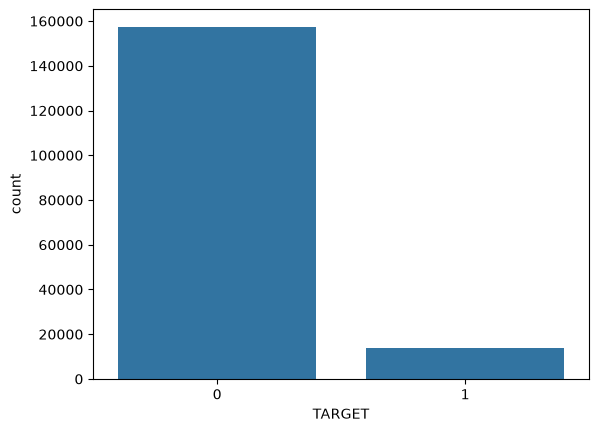

In [23]:
# The distribution of the target (default or not)
sns.countplot(data=train, x="TARGET")
plt.show()

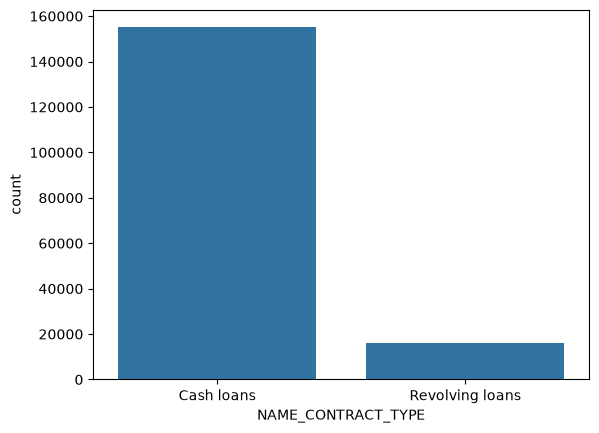

In [24]:
# The distribution of NAME_CONTRACT_TYPE
sns.countplot(data=train, x="NAME_CONTRACT_TYPE")
plt.show()

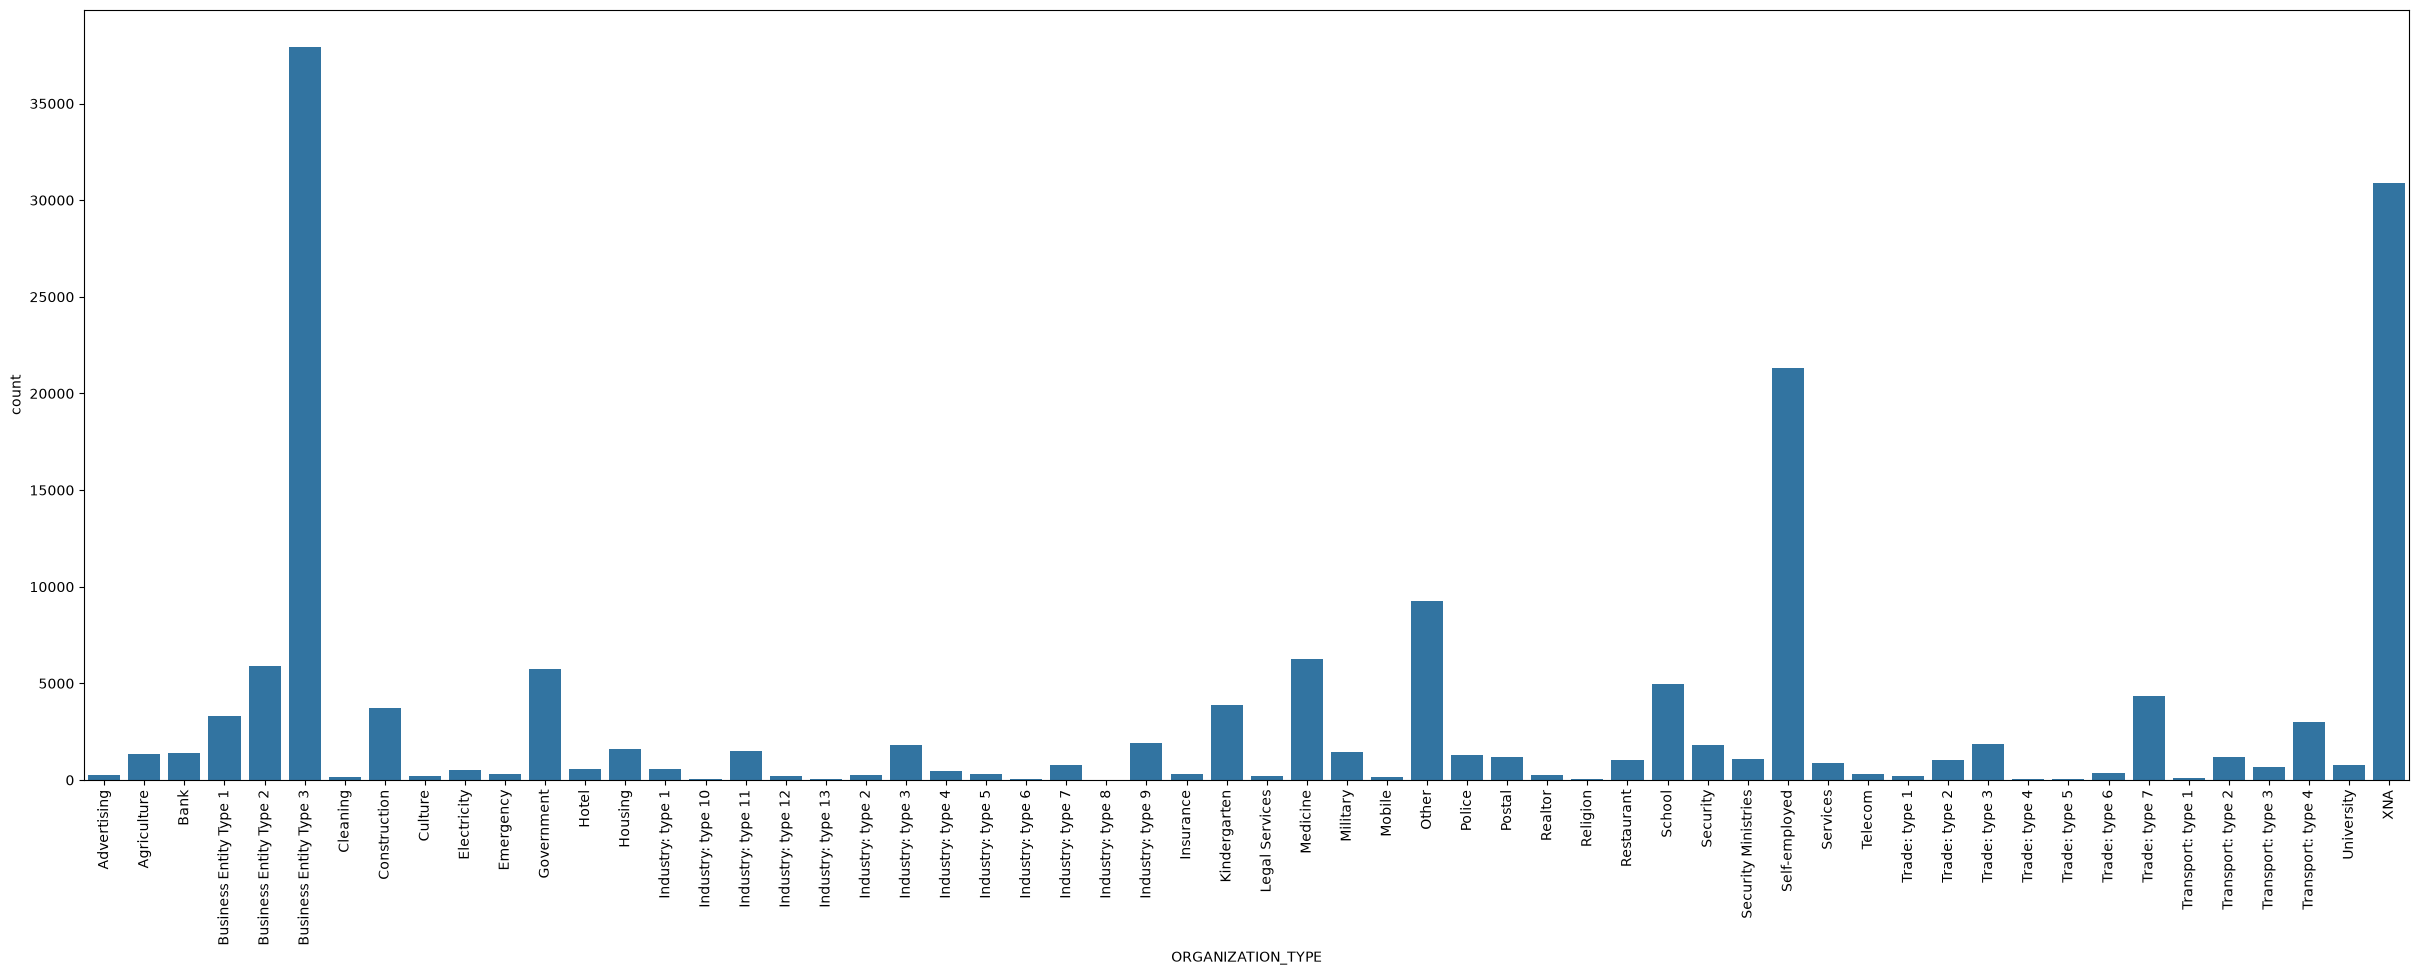

In [25]:
# The distribution of ORGANIZATION_TYPE
plt.figure(figsize=(30, 10))
sns.countplot(data=train, x="ORGANIZATION_TYPE")
plt.tick_params(axis="x", rotation=90)
plt.show()

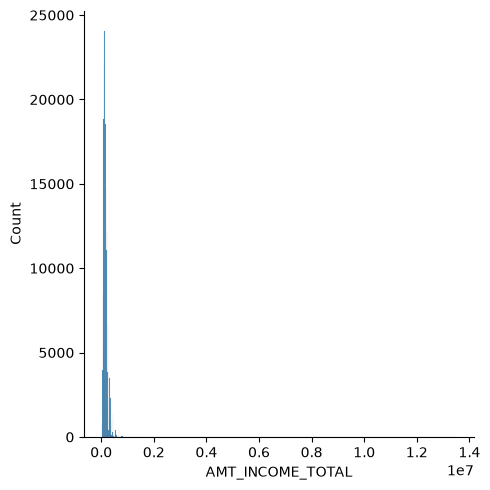

In [26]:
# The distribution of AMT_INCOME_TOTAL
sns.displot(data=train, x="AMT_INCOME_TOTAL")
plt.show()

There is a clear outlier in the AMT_INCOME_TOTAL

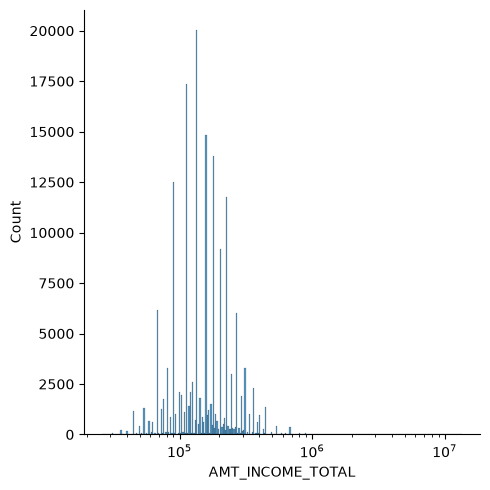

In [27]:
# The distribution of AMT_INCOME_TOTAL（Logarithmic transformation）
sns.displot(data=train, x="AMT_INCOME_TOTAL", log_scale=10)
plt.show()

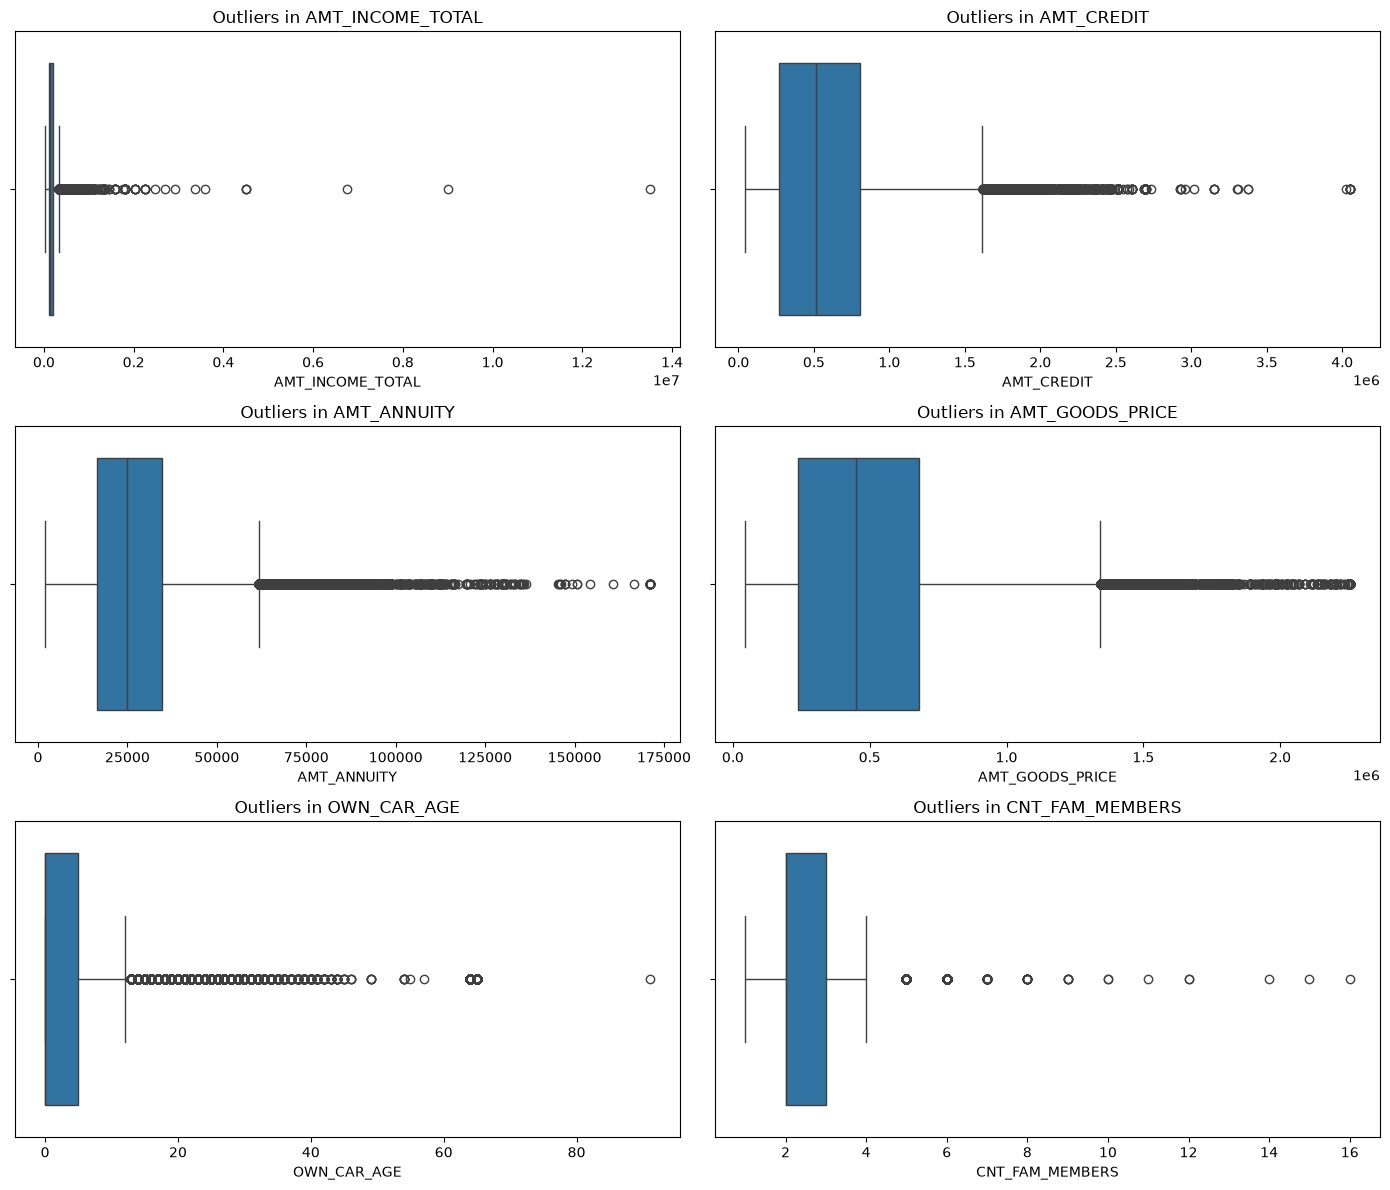

In [28]:
features = [
    'AMT_INCOME_TOTAL',
    'AMT_CREDIT',
    'AMT_ANNUITY',
    'AMT_GOODS_PRICE',
    'OWN_CAR_AGE',
    'CNT_FAM_MEMBERS'
]

fig, axes = plt.subplots(3, 2, figsize=(14, 12))

for col, ax in zip(features, axes.flatten()):
    sns.boxplot(x=train[col], ax=ax)
    ax.set_title(f'Outliers in {col}')

plt.tight_layout()
plt.show()

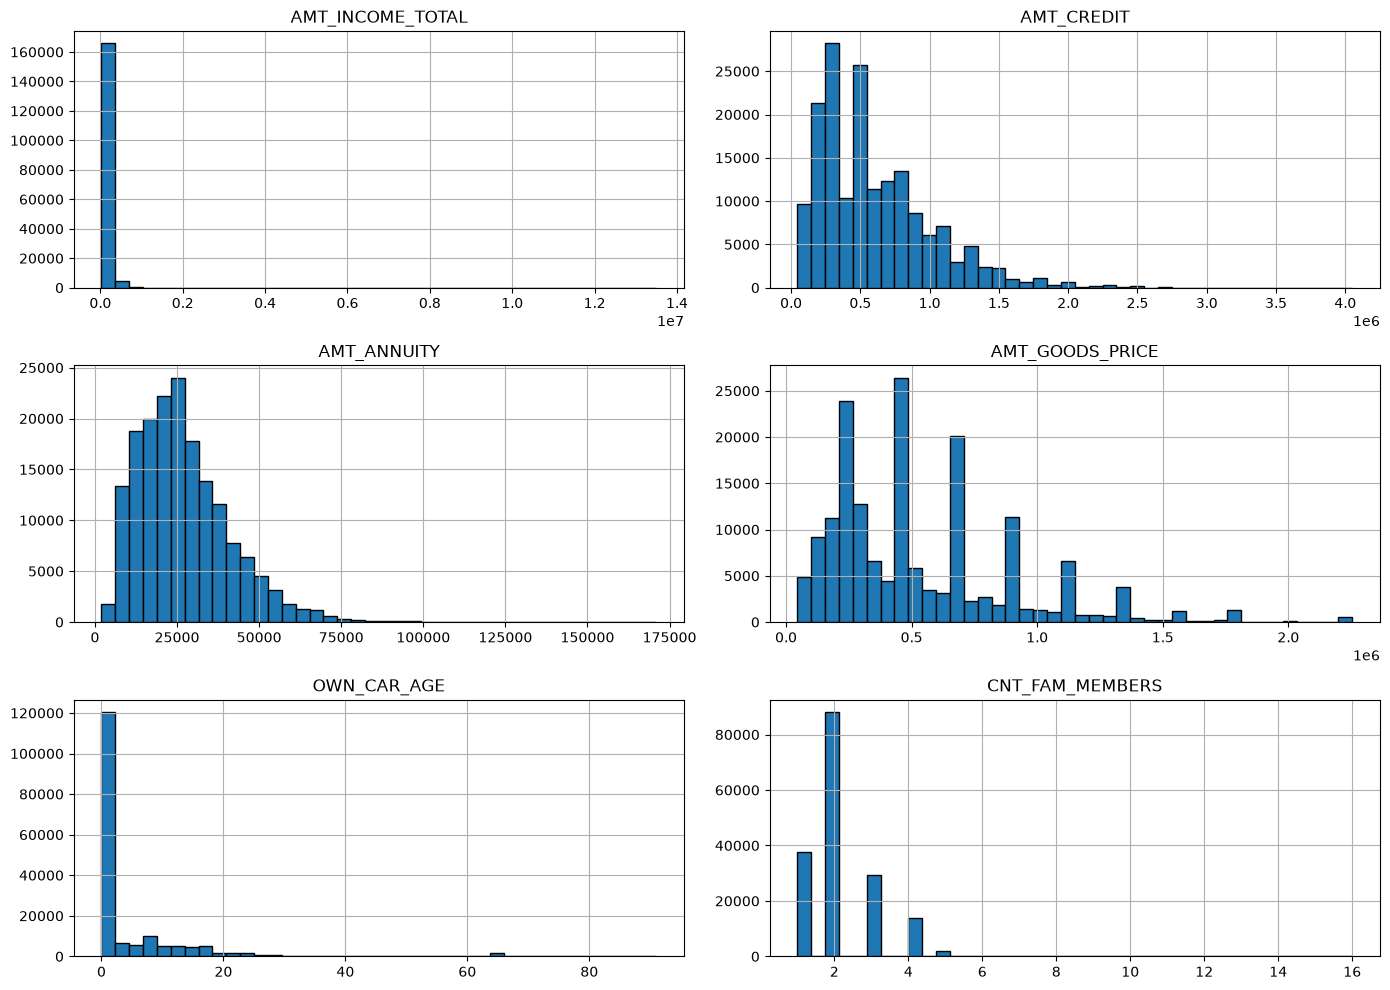

In [29]:
train[features].hist(
    figsize=(14, 10),
    bins=40,
    edgecolor='black'
)

plt.tight_layout()
plt.show()

In [30]:
# there is a clear visiable outlier in 'AMT_INCOME_TOTAL','AMT_CREDIT',  'AMT_ANNUITY', 'AMT_GOODS_PRICE'
# capping them
train_capped = train.copy()

features = [
    'AMT_INCOME_TOTAL',
    'AMT_CREDIT',
    'AMT_ANNUITY',
    'AMT_GOODS_PRICE'
]

for col in features:
    lower = train_capped[col].quantile(0.01)
    upper = train_capped[col].quantile(0.99)

    train_capped[col] = train_capped[col].clip(
        lower=lower,
        upper=upper
    )

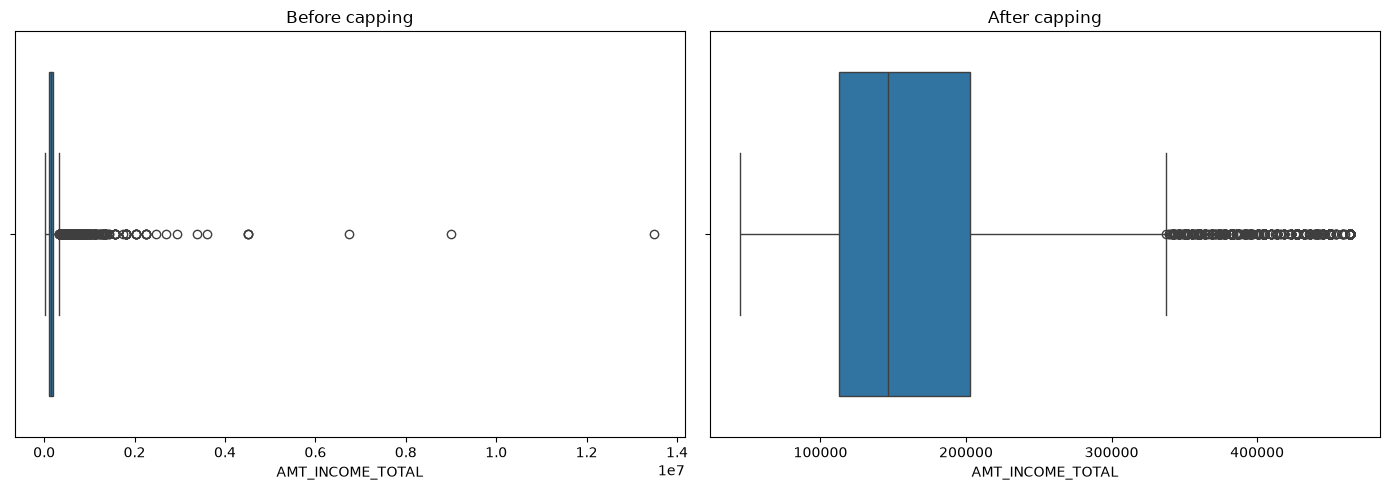

In [31]:
# comparing before and after 
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(x=train['AMT_INCOME_TOTAL'], ax=axes[0])
axes[0].set_title('Before capping')

sns.boxplot(x=train_capped['AMT_INCOME_TOTAL'], ax=axes[1])
axes[1].set_title('After capping')

plt.tight_layout()
plt.show()

### this outliners after removed does not look so good , so keep this as usual 
### But But But -  there is some information on the days_employed column as i come to search accross the internet about this dataset


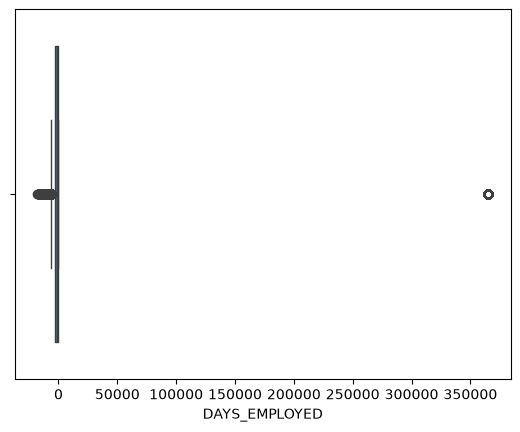

In [32]:
sns.boxplot(x=train['DAYS_EMPLOYED'])
plt.show()

### There is a value in the right most and the days employed value is 365243 which is not ususal :) 

In [33]:
# now use this information as fake employed date cause it can add some value to our model 
train['DAYS_EMPLOYED_FAKE'] = (
    train['DAYS_EMPLOYED'] == 365243
).astype(int)

In [34]:
# now fill the fake values with na- cause filling with 0 or any number will destroy :) the feature 
train['DAYS_EMPLOYED'] = train['DAYS_EMPLOYED'].replace(
    365243, np.nan
)

In [38]:
# adding extra featuers to the data to increase accuracy more 
train['AGE_YEARS'] = -train['DAYS_BIRTH'] / 365                       # days are negative, make years
train['CREDIT_INCOME'] = train['AMT_CREDIT'] / train['AMT_INCOME_TOTAL']   # loan size vs income
train['ANNUITY_INCOME'] = train['AMT_ANNUITY'] / train['AMT_INCOME_TOTAL'] # yearly payment vs income
train['CREDIT_TERM'] = train['AMT_ANNUITY'] / train['AMT_CREDIT']          # roughly: how fast repay
train['INCOME_PER_PERSON'] = train['AMT_INCOME_TOTAL'] / train['CNT_FAM_MEMBERS']
train['EMPLOYED_BIRTH'] = train['DAYS_EMPLOYED'] / train['DAYS_BIRTH']     # share of life employed


In [39]:
train.columns

Index(['SK_ID_CURR', 'NAME_CONTRACT_TYPE', 'CODE_GENDER', 'CNT_CHILDREN',
       'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE',
       'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS',
       'NAME_HOUSING_TYPE', 'REGION_POPULATION_RELATIVE', 'DAYS_BIRTH',
       'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'OWN_CAR_AGE',
       'FLAG_MOBIL', 'FLAG_EMP_PHONE', 'FLAG_WORK_PHONE', 'OCCUPATION_TYPE',
       'CNT_FAM_MEMBERS', 'REGION_RATING_CLIENT', 'ORGANIZATION_TYPE',
       'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3',
       'DAYS_LAST_PHONE_CHANGE', 'AMT_REQ_CREDIT_BUREAU_HOUR',
       'AMT_REQ_CREDIT_BUREAU_MON', 'AMT_REQ_CREDIT_BUREAU_QRT',
       'AMT_REQ_CREDIT_BUREAU_YEAR', 'TARGET', 'EXT_MEAN', 'EXT_MIN',
       'EXT_MAX', 'EXT_PROD', 'DAYS_EMPLOYED_FAKE', 'AGE_YEARS',
       'CREDIT_INCOME', 'ANNUITY_INCOME', 'CREDIT_TERM', 'INCOME_PER_PERSON',
       'EMPLOYED_BIRTH'],
      dtype='str')

In [40]:
train.describe()

,SK_ID_CURR,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,...,EXT_MIN,EXT_MAX,EXT_PROD,DAYS_EMPLOYED_FAKE,AGE_YEARS,CREDIT_INCOME,ANNUITY_INCOME,CREDIT_TERM,INCOME_PER_PERSON,EMPLOYED_BIRTH
count,171202.00000,171202.000000,1.712020e+05,1.712020e+05,171202.000000,1.712020e+05,171202.000000,171202.000000,140304.000000,171202.000000,...,1.712020e+05,171202.000000,1.712020e+05,171202.000000,171202.000000,171202.000000,171202.000000,171202.000000,1.712000e+05,140304.000000
mean,85600.50000,0.416490,1.683712e+05,5.991293e+05,27120.065953,5.380569e+05,0.020839,-16045.340504,-2388.583105,-4994.982524,...,3.817738e-01,0.635338,1.382954e-01,0.180477,43.959837,3.958324,0.181042,0.053732,9.298098e+04,0.157084
std,49421.90473,0.720138,1.072348e+05,4.028170e+05,14450.252689,3.685727e+05,0.013803,4363.792228,2336.564723,3525.760241,...,1.503318e-01,0.103254,8.065904e-02,0.384585,11.955595,2.688714,0.094628,0.022500,7.406180e+04,0.133467
min,0.00000,0.000000,2.610000e+04,4.500000e+04,1980.000000,4.500000e+04,0.000290,-25229.000000,-17912.000000,-24672.000000,...,8.173617e-08,0.057639,1.549621e-08,0.000000,21.021918,0.066667,0.003333,0.022076,2.812500e+03,0.000042
25%,42800.25000,0.000000,1.125000e+05,2.700000e+05,16546.500000,2.385000e+05,0.010006,-19686.000000,-3192.000000,-7490.000000,...,2.670855e-01,0.537070,7.461190e-02,0.000000,34.027397,2.018667,0.114784,0.036900,4.800000e+04,0.056252
50%,85600.50000,0.000000,1.462500e+05,5.146020e+05,24916.500000,4.500000e+05,0.018850,-15778.000000,-1650.000000,-4515.000000,...,4.311918e-01,0.635479,1.367358e-01,0.000000,43.227397,3.267273,0.162961,0.050000,7.500000e+04,0.118787
75%,128400.75000,1.000000,2.025000e+05,8.086500e+05,34600.500000,6.795000e+05,0.028663,-12420.000000,-771.000000,-2008.000000,...,5.058576e-01,0.714724,1.900922e-01,0.000000,53.934247,5.166133,0.229300,0.064141,1.125000e+05,0.219661
max,171201.00000,14.000000,1.350000e+07,4.050000e+06,170986.500000,2.254500e+06,0.072508,-7673.000000,-1.000000,0.000000,...,8.068084e-01,0.947649,5.969390e-01,1.000000,69.120548,49.227200,1.570600,0.124430,6.750000e+06,0.728811


## Now We Are Good To GO To Proceed With The Data To Fit The Models . Train tets split

In [41]:
# Importing libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

In [42]:
X = train.drop("TARGET", axis=1)
y = train["TARGET"]
X_test = test.copy()

In [43]:
X_test

,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,REGION_RATING_CLIENT,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,171202,Cash loans,F,1,144000.0,961146.0,28233.0,688500.0,Working,Higher education,...,2,Kindergarten,NaN,0.720416,NaN,-1.0,NaN,NaN,NaN,NaN
1,171203,Cash loans,F,0,103500.0,296280.0,16069.5,225000.0,Working,Secondary / secondary special,...,2,School,NaN,0.287306,NaN,-212.0,NaN,NaN,NaN,NaN
2,171204,Cash loans,F,1,180000.0,183694.5,11236.5,139500.0,Commercial associate,Secondary / secondary special,...,3,Trade: type 7,NaN,0.352456,0.389339,-428.0,0.0,1.0,1.0,1.0
3,171205,Revolving loans,F,2,225000.0,450000.0,22500.0,450000.0,Working,Higher education,...,2,Business Entity Type 3,NaN,0.470384,0.217629,-442.0,0.0,0.0,0.0,3.0
4,171206,Cash loans,F,2,144000.0,545040.0,26640.0,450000.0,Working,Higher education,...,3,Business Entity Type 3,0.269931,0.373133,NaN,-1333.0,0.0,0.0,0.0,3.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
61495,232697,Cash loans,F,0,315000.0,1288350.0,37800.0,1125000.0,Commercial associate,Higher education,...,2,Trade: type 7,0.263678,0.018172,0.307737,-1.0,0.0,1.0,1.0,1.0
61496,232698,Cash loans,F,0,90000.0,273636.0,15408.0,247500.0,Working,Higher education,...,2,Self-employed,NaN,0.668578,0.434733,-2732.0,0.0,0.0,0.0,0.0
61497,232699,Cash loans,F,0,144000.0,291384.0,26725.5,270000.0,Commercial associate,Higher education,...,2,Business Entity Type 3,0.510226,0.574151,NaN,-615.0,0.0,0.0,1.0,0.0
61498,232700,Cash loans,F,1,193500.0,746280.0,59094.0,675000.0,State servant,Higher education,...,3,Other,0.353295,0.226714,NaN,-1610.0,0.0,0.0,1.0,3.0


In [44]:
# splitting the data into train and validation set
# Split the original data into the training data and the validation data
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.3, stratify=y, random_state=0)

In [45]:
X_train

,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,EXT_MIN,EXT_MAX,EXT_PROD,DAYS_EMPLOYED_FAKE,AGE_YEARS,CREDIT_INCOME,ANNUITY_INCOME,CREDIT_TERM,INCOME_PER_PERSON,EMPLOYED_BIRTH
101303,101303,Cash loans,F,0,112500.0,417024.0,17113.5,360000.0,Working,Secondary / secondary special,...,0.505858,0.586161,0.159249,0,42.868493,3.706880,0.152120,0.041037,56250.0,0.012207
163384,163384,Cash loans,F,0,144000.0,1230565.5,40797.0,1102500.0,Working,Higher education,...,0.283177,0.686778,0.068843,0,46.493151,8.545594,0.283313,0.033153,72000.0,0.111786
28250,28250,Cash loans,F,0,114750.0,900000.0,26316.0,900000.0,Commercial associate,Secondary / secondary special,...,0.537070,0.735400,0.222497,0,35.528767,7.843137,0.229333,0.029240,57375.0,0.313155
104007,104007,Cash loans,F,0,180000.0,1125000.0,32895.0,1125000.0,Working,Secondary / secondary special,...,0.573841,0.600658,0.204736,0,43.498630,6.250000,0.182750,0.029240,90000.0,0.048624
49129,49129,Cash loans,F,0,139500.0,499500.0,22131.0,499500.0,Pensioner,Secondary / secondary special,...,0.024192,0.505858,0.003617,1,60.254795,3.580645,0.158645,0.044306,69750.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
164868,164868,Cash loans,M,0,202500.0,521280.0,41926.5,450000.0,Working,Incomplete higher,...,0.068251,0.530355,0.013577,0,28.668493,2.574222,0.207044,0.080430,202500.0,0.121942
102265,102265,Cash loans,F,0,45000.0,229500.0,11718.0,229500.0,Working,Secondary / secondary special,...,0.319587,0.537070,0.086826,0,47.682192,5.100000,0.260400,0.051059,22500.0,0.069754
51819,51819,Cash loans,F,0,108000.0,99000.0,10273.5,99000.0,Pensioner,Secondary / secondary special,...,0.415631,0.694093,0.145933,1,62.967123,0.916667,0.095125,0.103773,54000.0,NaN
21834,21834,Cash loans,F,0,225000.0,1585899.0,41962.5,1417500.0,Working,Secondary / secondary special,...,0.505858,0.770087,0.221990,0,62.926027,7.048440,0.186500,0.026460,112500.0,0.115552


In [46]:
# converting test text data into categorical data 
test_text_cols=X_test.select_dtypes(
    include=['object', 'str', 'string']
).columns

for test_col in test_text_cols:
    X_test[test_col] = X_test[test_col].astype('category')


In [47]:
X_test.select_dtypes(
    include=['object', 'str', 'string']
).columns

Index([], dtype='str')

# In the tutorial notebook we see that the accuracy with Logistic Regression , Random Forest is pretty Low , So I Am Using XGboost directly herer

In [48]:
# training XGBOOST
import xgboost as xgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score


In [49]:
X_train

,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,EXT_MIN,EXT_MAX,EXT_PROD,DAYS_EMPLOYED_FAKE,AGE_YEARS,CREDIT_INCOME,ANNUITY_INCOME,CREDIT_TERM,INCOME_PER_PERSON,EMPLOYED_BIRTH
101303,101303,Cash loans,F,0,112500.0,417024.0,17113.5,360000.0,Working,Secondary / secondary special,...,0.505858,0.586161,0.159249,0,42.868493,3.706880,0.152120,0.041037,56250.0,0.012207
163384,163384,Cash loans,F,0,144000.0,1230565.5,40797.0,1102500.0,Working,Higher education,...,0.283177,0.686778,0.068843,0,46.493151,8.545594,0.283313,0.033153,72000.0,0.111786
28250,28250,Cash loans,F,0,114750.0,900000.0,26316.0,900000.0,Commercial associate,Secondary / secondary special,...,0.537070,0.735400,0.222497,0,35.528767,7.843137,0.229333,0.029240,57375.0,0.313155
104007,104007,Cash loans,F,0,180000.0,1125000.0,32895.0,1125000.0,Working,Secondary / secondary special,...,0.573841,0.600658,0.204736,0,43.498630,6.250000,0.182750,0.029240,90000.0,0.048624
49129,49129,Cash loans,F,0,139500.0,499500.0,22131.0,499500.0,Pensioner,Secondary / secondary special,...,0.024192,0.505858,0.003617,1,60.254795,3.580645,0.158645,0.044306,69750.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
164868,164868,Cash loans,M,0,202500.0,521280.0,41926.5,450000.0,Working,Incomplete higher,...,0.068251,0.530355,0.013577,0,28.668493,2.574222,0.207044,0.080430,202500.0,0.121942
102265,102265,Cash loans,F,0,45000.0,229500.0,11718.0,229500.0,Working,Secondary / secondary special,...,0.319587,0.537070,0.086826,0,47.682192,5.100000,0.260400,0.051059,22500.0,0.069754
51819,51819,Cash loans,F,0,108000.0,99000.0,10273.5,99000.0,Pensioner,Secondary / secondary special,...,0.415631,0.694093,0.145933,1,62.967123,0.916667,0.095125,0.103773,54000.0,NaN
21834,21834,Cash loans,F,0,225000.0,1585899.0,41962.5,1417500.0,Working,Secondary / secondary special,...,0.505858,0.770087,0.221990,0,62.926027,7.048440,0.186500,0.026460,112500.0,0.115552


In [50]:
model = xgb.XGBClassifier(
    n_estimators=5000,
    learning_rate=0.03,
    max_depth=5,
    min_child_weight=30,
    subsample=0.8,
    colsample_bytree=0.5,
    reg_alpha=0.1,
    reg_lambda=5,
    tree_method="hist",
    enable_categorical=True,
    eval_metric="auc",
    early_stopping_rounds=100,
    n_jobs=-1,
    random_state=42
)

In [51]:
model.fit(
    X_train, y_train,
    eval_set=[(X_valid, y_valid)],
    verbose=False
)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.5
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",100
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'auc'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [52]:
# Predict probabilities
y_pred = model.predict_proba(X_valid)[:, 1]

# Evaluate model
auc = roc_auc_score(y_valid, y_pred)
print(f"Validation AUC: {auc:.4f}")
print(f"Best iteration: {model.best_iteration}")

Validation AUC: 0.7479
Best iteration: 651


,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,EXT_MEAN,EXT_MIN,EXT_MAX,EXT_PROD,DAYS_EMPLOYED_FAKE
101303,101303,Cash loans,F,0,112500.0,417024.0,17113.5,360000.0,Working,Secondary / secondary special,...,-1094.0,0.0,0.0,0.0,1.0,0.543030,0.505858,0.586161,0.159249,0
163384,163384,Cash loans,F,0,144000.0,1230565.5,40797.0,1102500.0,Working,Higher education,...,-1464.0,0.0,0.0,0.0,1.0,0.441314,0.283177,0.686778,0.068843,0
28250,28250,Cash loans,F,0,114750.0,900000.0,26316.0,900000.0,Commercial associate,Secondary / secondary special,...,-1908.0,0.0,1.0,0.0,0.0,0.611936,0.537070,0.735400,0.222497,0
104007,104007,Cash loans,F,0,180000.0,1125000.0,32895.0,1125000.0,Working,Secondary / secondary special,...,-1357.0,0.0,0.0,0.0,1.0,0.589494,0.573841,0.600658,0.204736,0
49129,49129,Cash loans,F,0,139500.0,499500.0,22131.0,499500.0,Pensioner,Secondary / secondary special,...,-521.0,0.0,0.0,0.0,7.0,0.275211,0.024192,0.505858,0.003617,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
164868,164868,Cash loans,M,0,202500.0,521280.0,41926.5,450000.0,Working,Incomplete higher,...,-271.0,0.0,0.0,0.0,0.0,0.324567,0.068251,0.530355,0.013577,0
102265,102265,Cash loans,F,0,45000.0,229500.0,11718.0,229500.0,Working,Secondary / secondary special,...,-97.0,0.0,0.0,0.0,1.0,0.454172,0.319587,0.537070,0.086826,0
51819,51819,Cash loans,F,0,108000.0,99000.0,10273.5,99000.0,Pensioner,Secondary / secondary special,...,-356.0,0.0,0.0,0.0,4.0,0.538527,0.415631,0.694093,0.145933,1
21834,21834,Cash loans,F,0,225000.0,1585899.0,41962.5,1417500.0,Working,Secondary / secondary special,...,-1395.0,0.0,0.0,0.0,3.0,0.615267,0.505858,0.770087,0.221990,0


## The Score Is Still .73 :( 

In [52]:
xgb_v2 = xgb.XGBClassifier(
    n_estimators=5000,
    learning_rate=0.03,
    max_depth=5,
    min_child_weight=30,
    subsample=0.8,
    colsample_bytree=0.5,
    reg_alpha=0.1,
    reg_lambda=5,
    tree_method="hist",
    enable_categorical=True,
    eval_metric="auc",
    early_stopping_rounds=100,
    n_jobs=-1,
    random_state=42
)

In [53]:
xgb_v2.fit(
    X_train, y_train,
    eval_set=[(X_valid, y_valid)],
    verbose=False
)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.5
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",100
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'auc'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [56]:
# Predict probabilities
y_pred = xgb_v2.predict_proba(X_valid)[:, 1]

# Evaluate model
auc = roc_auc_score(y_valid, y_pred)
print(f"Validation AUC: {auc:.4f}")
print(f"Best iteration: {xgb_v2.best_iteration}")

Validation AUC: 0.7554
Best iteration: 774


In [57]:
xgb_v3 = xgb.XGBClassifier(
    n_estimators=50000,
    learning_rate=0.03,
    max_depth=50,
    min_child_weight=30,
    subsample=0.8,
    colsample_bytree=0.5,
    reg_alpha=0.1,
    reg_lambda=5,
    tree_method="hist",
    enable_categorical=True,
    eval_metric="auc",
    early_stopping_rounds=100,
    n_jobs=-1,
    random_state=42
)

xgb_v3.fit(
    X_train, y_train,
    eval_set=[(X_valid, y_valid)],
    verbose=False
)

# Predict probabilities
y_pred = xgb_v3.predict_proba(X_valid)[:, 1]

# Evaluate model
auc = roc_auc_score(y_valid, y_pred)
print(f"Validation AUC: {auc:.4f}")
print(f"Best iteration: {xgb_v2.best_iteration}")

Validation AUC: 0.7514
Best iteration: 774


In [58]:
xgb_v4 = xgb.XGBClassifier(
    n_estimators=5000,
    learning_rate=0.01,
    max_depth=5,
    min_child_weight=30,
    subsample=0.8,
    colsample_bytree=0.5,
    reg_alpha=0.1,
    reg_lambda=5,
    tree_method="hist",
    enable_categorical=True,
    eval_metric="auc",
    early_stopping_rounds=100,
    n_jobs=-1,
    random_state=42
)

xgb_v4.fit(
    X_train, y_train,
    eval_set=[(X_valid, y_valid)],
    verbose=False
)

# Predict probabilities
y_pred = xgb_v4.predict_proba(X_valid)[:, 1]

# Evaluate model
auc = roc_auc_score(y_valid, y_pred)
print(f"Validation AUC: {auc:.4f}")
print(f"Best iteration: {xgb_v4.best_iteration}")

Validation AUC: 0.7560
Best iteration: 2141


## Saving the model

## Preprocessing the test data

In [59]:
# have to add 5 extra column/features to the X_test that i added to the model 
# Combine external credit scores
ext_cols = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]

X_test["EXT_MEAN"] = X_test[ext_cols].mean(axis=1)
X_test["EXT_MIN"] = X_test[ext_cols].min(axis=1)
X_test["EXT_MAX"] = X_test[ext_cols].max(axis=1)
X_test["EXT_PROD"] = X_test[ext_cols].prod(axis=1)

# Preserve information about the special employment value
X_test["DAYS_EMPLOYED_FAKE"] = (X_test["DAYS_EMPLOYED"] == 365243).astype(int)

# Replace the special value with missing data
X_test["DAYS_EMPLOYED"] = X_test["DAYS_EMPLOYED"].replace(365243, np.nan)


# adding additional feature
# converting features

X_test['AGE_YEARS'] = -X_test['DAYS_BIRTH'] / 365                       # days are negative, make years
X_test['CREDIT_INCOME'] = X_test['AMT_CREDIT'] / X_test['AMT_INCOME_TOTAL']   # loan size vs income
X_test['ANNUITY_INCOME'] = X_test['AMT_ANNUITY'] / X_test['AMT_INCOME_TOTAL'] # yearly payment vs income
X_test['CREDIT_TERM'] = X_test['AMT_ANNUITY'] / X_test['AMT_CREDIT']          # roughly: how fast repay
X_test['INCOME_PER_PERSON'] = X_test['AMT_INCOME_TOTAL'] / X_test['CNT_FAM_MEMBERS']
X_test['EMPLOYED_BIRTH'] = X_test['DAYS_EMPLOYED'] / X_test['DAYS_BIRTH']     # share of life employed


In [61]:
# Make predictions for the test data
# Change model name if needed
pred = xgb_v3.predict_proba(X_test)[:, 1]

In [62]:
# Put the prediction into the format of submission
sample_sub['TARGET'] = pred
sample_sub

,SK_ID_CURR,TARGET
0,171202,0.013359
1,171203,0.062545
2,171204,0.127151
3,171205,0.085223
4,171206,0.160224
...,...,...
61495,232697,0.271219
61496,232698,0.022962
61497,232699,0.039950
61498,232700,0.152313


In [63]:
# Create the "output" directory if it doesn't exist
output_dir = current_dir / "output"
os.makedirs(output_dir, exist_ok=True)

# Specify the new output file path
output_file = output_dir / "submission.csv"

# Save the CSV file to the "output" directory
sample_sub.to_csv(output_file, index=False)